In [1]:
# Установка Blender через пакетный менеджер Windows (если еще не установлен)
!winget install BlenderFoundation.Blender -e --accept-source-agreements --accept-package-agreements

# Установка BlenderProc в текущее venv
%pip install blenderproc

Найден существующий установленный пакет. Попытка обновления установленного пакета...
Доступные обновления не найдены.
Более новые версии пакетов недоступны в настроенных источниках.
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import os
import ssl
import urllib.request
import zipfile
from pathlib import Path

BLENDER_DIR = Path(r"D:\Blender")
BLENDER_EXE = BLENDER_DIR / "blender.exe"

if not BLENDER_EXE.exists():
    print("Скачиваем портативный Blender 4.2 LTS на диск D:...")
    BLENDER_DIR.mkdir(parents=True, exist_ok=True)
    zip_path = Path(r"D:\blender_portable.zip")

    # Игнорируем перехват SSL антивирусом
    ctx = ssl.create_default_context()
    ctx.check_hostname = False
    ctx.verify_mode = ssl.CERT_NONE

    url = "https://download.blender.org/release/Blender4.2/blender-4.2.1-windows-x64.zip"

    # Потоковая загрузка с прогрессом
    with urllib.request.urlopen(url, context=ctx) as response, open(zip_path, "wb") as out_file:
        total_size = int(response.info().get("Content-Length", 0))
        downloaded = 0
        chunk_size = 1024 * 1024 * 4  # 4 MB
        while True:
            chunk = response.read(chunk_size)
            if not chunk:
                break
            out_file.write(chunk)
            downloaded += len(chunk)
            if total_size > 0:
                print(f"\rЗагружено: {downloaded / 1024**2:.1f} / {total_size / 1024**2:.1f} MB ({(downloaded/total_size)*100:.1f}%)", end="")

    print("\nРаспаковка архива в D:\\Blender...")
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        # Извлекаем содержимое внутренней папки архива напрямую в D:\Blender
        for member in zip_ref.infolist():
            parts = Path(member.filename).parts
            if len(parts) > 1:
                target_path = BLENDER_DIR / Path(*parts[1:])
                if member.is_dir():
                    target_path.mkdir(parents=True, exist_ok=True)
                else:
                    target_path.parent.mkdir(parents=True, exist_ok=True)
                    with zip_ref.open(member) as src, open(target_path, "wb") as dst:
                        dst.write(src.read())

    if zip_path.exists():
        zip_path.unlink()
    print(f"[УСПЕХ] Blender готов к работе: {BLENDER_EXE}")
else:
    print(f"Blender уже готов: {BLENDER_EXE}")

Скачиваем портативный Blender 4.2 LTS на диск D:...
Загружено: 365.9 / 365.9 MB (100.0%)
Распаковка архива в D:\Blender...
[УСПЕХ] Blender готов к работе: D:\Blender\blender.exe


In [10]:
%%writefile generator_blender.py
import bpy
import math
import random
from pathlib import Path
from mathutils import Vector
from bpy_extras.object_utils import world_to_camera_view

# ==========================================
# 1. Инициализация и настройка OptiX Cycles
# ==========================================
bpy.ops.wm.read_factory_settings(use_empty=True)
scene = bpy.context.scene

scene.render.engine = 'CYCLES'
cycles = scene.cycles
cycles.device = 'GPU'
cycles.samples = 32
cycles.preview_samples = 16
cycles.use_denoising = True

prefs = bpy.context.preferences.addons['cycles'].preferences
prefs.compute_device_type = 'OPTIX'
prefs.get_devices()
for dev in prefs.devices:
    if dev.type == 'OPTIX':
        dev.use = True

# Физический мир с повышенным демпфированием, чтобы таблетки не разлетались
if not scene.rigidbody_world:
    bpy.ops.rigidbody.world_add()
rbw = scene.rigidbody_world
rbw.substeps_per_frame = 25
rbw.solver_iterations = 40

# ==========================================
# 2. Стол (Пассивная физика)
# ==========================================
bpy.ops.mesh.primitive_cube_add(size=1.0, location=(0, 0, -0.05))
ground = bpy.context.active_object
ground.name = "Table"
ground.scale = (2.0, 2.0, 0.1)
bpy.ops.rigidbody.object_add()
ground.rigid_body.type = 'PASSIVE'
ground.rigid_body.collision_shape = 'BOX'
ground.rigid_body.friction = 0.95

# Материал столешницы (матовый нейтральный графит)
mat_ground = bpy.data.materials.new(name="Table_Mat")
mat_ground.use_nodes = True
bsdf_g = mat_ground.node_tree.nodes.get("Principled BSDF")
bsdf_g.inputs['Base Color'].default_value = (0.15, 0.15, 0.17, 1.0)
bsdf_g.inputs['Roughness'].default_value = 0.8
ground.data.materials.append(mat_ground)

# ==========================================
# 3. Фабрика процедурных материалов
# ==========================================
def get_chalk_material(name, color_rgb):
    """Шейдер матового прессованного мела с легким подповерхностным рассеиванием"""
    mat = bpy.data.materials.new(name=name)
    mat.use_nodes = True
    bsdf = mat.node_tree.nodes.get("Principled BSDF")
    bsdf.inputs['Base Color'].default_value = (*color_rgb, 1.0)
    bsdf.inputs['Roughness'].default_value = 0.75
    # Легкий эффект порошка
    if 'Subsurface Weight' in bsdf.inputs:
        bsdf.inputs['Subsurface Weight'].default_value = 0.08
    return mat

def get_gelatin_material(name, color_rgb):
    """Шейдер глянцевой желатиновой капсулы с лаковым слоем"""
    mat = bpy.data.materials.new(name=name)
    mat.use_nodes = True
    bsdf = mat.node_tree.nodes.get("Principled BSDF")
    bsdf.inputs['Base Color'].default_value = (*color_rgb, 1.0)
    bsdf.inputs['Roughness'].default_value = 0.12
    bsdf.inputs['IOR'].default_value = 1.48
    if 'Coat Weight' in bsdf.inputs:
        bsdf.inputs['Coat Weight'].default_value = 1.0
        bsdf.inputs['Coat Roughness'].default_value = 0.05
    return mat

# Базовые цветовые палитры фармакологии
PALETTE = {
    "white": (0.92, 0.92, 0.92),
    "yellow": (0.95, 0.82, 0.15),
    "blue": (0.05, 0.35, 0.85),
    "red": (0.85, 0.10, 0.10),
    "green": (0.12, 0.65, 0.25),
    "orange": (0.95, 0.45, 0.05)
}

# ==========================================
# 4. Процедурные генераторы геометрии
# ==========================================
def create_round_tablet(name, loc, rot, has_score=True):
    """Круглая таблетка с фаской и процедурной риской (класс 1: tablet)"""
    radius = random.uniform(0.009, 0.012)
    depth = random.uniform(0.004, 0.006)
    
    bpy.ops.mesh.primitive_cylinder_add(
        vertices=64, radius=radius, depth=depth, location=loc, rotation=rot
    )
    obj = bpy.context.active_object
    obj.name = name

    # Булева насечка (риска по центру)
    if has_score:
        bpy.ops.mesh.primitive_cube_add(
            size=1.0, 
            location=(loc[0], loc[1], loc[2] + depth * 0.48),
            rotation=rot
        )
        cutter = bpy.context.active_object
        cutter.scale = (radius * 2.2, 0.0006, depth * 0.25)
        
        bool_mod = obj.modifiers.new(name="Score", type='BOOLEAN')
        bool_mod.operation = 'DIFFERENCE'
        bool_mod.object = cutter
        
        bpy.context.view_layer.objects.active = obj
        bpy.ops.object.modifier_apply(modifier="Score")
        bpy.data.objects.remove(cutter, do_unlink=True)

    # Скругление фаски
    bevel = obj.modifiers.new(name="Bevel", type='BEVEL')
    bevel.width = 0.0009
    bevel.segments = 3
    bpy.ops.object.modifier_apply(modifier="Bevel")
    bpy.ops.object.shade_smooth()

    # Назначаем случайный цвет мела
    color_name = random.choice(["white", "yellow", "green", "orange"])
    obj.data.materials.append(get_chalk_material(f"Mat_{name}", PALETTE[color_name]))
    return obj

def create_oval_tablet(name, loc, rot):
    """Вытянутая овальная таблетка (класс 1: tablet)"""
    obj = create_round_tablet(name, loc, rot, has_score=False)
    # Вытягиваем в эллипс
    obj.scale = (1.55, 1.0, 1.0)
    bpy.context.view_layer.objects.active = obj
    bpy.ops.object.transform_apply(scale=True)
    return obj

def create_two_tone_capsule(name, loc, rot):
    """Двухцветная желатиновая капсула со стыком (класс 0: capsule)"""
    radius = random.uniform(0.0045, 0.0055)
    depth = random.uniform(0.016, 0.020)
    
    bpy.ops.mesh.primitive_cylinder_add(
        vertices=48, radius=radius, depth=depth, location=loc, rotation=rot
    )
    obj = bpy.context.active_object
    obj.name = name

    # Скругляем полусферические торцы
    bevel = obj.modifiers.new(name="Capsule_Bevel", type='BEVEL')
    bevel.width = radius * 0.95
    bevel.segments = 8
    bpy.ops.object.modifier_apply(modifier="Capsule_Bevel")
    bpy.ops.object.shade_smooth()

    # Два цвета (половинки капсулы)
    col1 = random.choice(["blue", "red", "green", "orange"])
    col2 = random.choice(["white", "yellow"])
    mat_top = get_gelatin_material(f"Mat_Top_{name}", PALETTE[col1])
    mat_bottom = get_gelatin_material(f"Mat_Bot_{name}", PALETTE[col2])
    obj.data.materials.append(mat_top)
    obj.data.materials.append(mat_bottom)

    # Назначаем полигонам разные слоты по локальной оси Z (до/после экватора)
    for poly in obj.data.polygons:
        poly.material_index = 0 if poly.center.z >= 0 else 1

    return obj

# ==========================================
# 5. Спавн пачки лекарств (от 3 до 6 штук)
# ==========================================
pills_data = []
spawn_types = ['round', 'round_score', 'oval', 'capsule', 'capsule']
random.shuffle(spawn_types)
num_items = random.randint(3, 5)

for i in range(num_items):
    p_type = spawn_types[i]
    loc = (random.uniform(-0.015, 0.015), random.uniform(-0.015, 0.015), 0.03 + i * 0.018)
    rot = (random.uniform(0, 3.14), random.uniform(0, 3.14), random.uniform(0, 3.14))

    if p_type == 'round':
        obj = create_round_tablet(f"pill_{i}", loc, rot, has_score=False)
        cls_id = 1
    elif p_type == 'round_score':
        obj = create_round_tablet(f"pill_{i}", loc, rot, has_score=True)
        cls_id = 1
    elif p_type == 'oval':
        obj = create_oval_tablet(f"pill_{i}", loc, rot)
        cls_id = 1
    else:
        obj = create_two_tone_capsule(f"pill_{i}", loc, rot)
        cls_id = 0

    # Настройка активного твердого тела
    bpy.ops.rigidbody.object_add()
    obj.rigid_body.type = 'ACTIVE'
    obj.rigid_body.collision_shape = 'CONVEX_HULL'
    obj.rigid_body.mass = 0.003
    obj.rigid_body.friction = 0.8
    obj.rigid_body.linear_damping = 0.65
    obj.rigid_body.angular_damping = 0.65

    pills_data.append({"obj": obj, "class_id": cls_id})

# ==========================================
# 6. Симуляция падения и заморозка
# ==========================================
for frame in range(1, 75):
    scene.frame_set(frame)

depsgraph = bpy.context.evaluated_depsgraph_get()
for item in pills_data:
    obj = item["obj"]
    eval_obj = obj.evaluated_get(depsgraph)
    obj.matrix_world = eval_obj.matrix_world.copy()
    obj.rigid_body.enabled = False

scene.frame_set(1)
bpy.context.view_layer.update()

# ==========================================
# 7. Свет и Камера со случайным ракурсом
# ==========================================
# Мягкий ключевой свет
light_data = bpy.data.lights.new(name="Main_Light", type='POINT')
light_data.energy = random.uniform(50.0, 75.0)
light_data.shadow_soft_size = 0.035
light_obj = bpy.data.objects.new(name="Main_Light", object_data=light_data)
scene.collection.objects.link(light_obj)
light_obj.location = (random.uniform(-0.1, 0.1), random.uniform(-0.15, -0.05), random.uniform(0.28, 0.38))

# Камера
cam_data = bpy.data.cameras.new(name="Camera")
cam_data.lens = 50
cam_obj = bpy.data.objects.new(name="Camera", object_data=cam_data)
scene.collection.objects.link(cam_obj)
scene.camera = cam_obj

# Случайный наклон и радиус камеры вокруг центра
cam_dist = random.uniform(0.20, 0.26)
cam_angle = random.uniform(math.radians(35), math.radians(65))
cam_z = cam_dist * math.sin(cam_angle)
cam_y = -cam_dist * math.cos(cam_angle)
cam_x = random.uniform(-0.04, 0.04)
cam_obj.location = (cam_x, cam_y, cam_z)

# Фокусировка на центр скопления
target = bpy.data.objects.new("Focus_Target", None)
scene.collection.objects.link(target)
target.location = (0, 0, 0.005)

track = cam_obj.constraints.new(type='TRACK_TO')
track.target = target
track.track_axis = 'TRACK_NEGATIVE_Z'
track.up_axis = 'UP_Y'

bpy.context.view_layer.update()
scene.render.resolution_x = 640
scene.render.resolution_y = 640

# ==========================================
# 8. Алгоритм Convex Hull и экспорт YOLO-seg
# ==========================================
def get_monotone_convex_hull(points):
    """Andrew's Monotone Chain 2D Convex Hull"""
    pts = sorted(set(points))
    if len(pts) <= 2:
        return pts
    def cross(o, a, b):
        return (a[0] - o[0]) * (b[1] - o[1]) - (a[1] - o[1]) * (b[0] - o[0])
    
    lower = []
    for p in pts:
        while len(lower) >= 2 and cross(lower[-2], lower[-1], p) <= 0:
            lower.pop()
        lower.append(p)
    upper = []
    for p in reversed(pts):
        while len(upper) >= 2 and cross(upper[-2], upper[-1], p) <= 0:
            upper.pop()
        upper.append(p)
    return lower[:-1] + upper[:-1]

def calculate_yolo_seg_and_bbox(scene, camera, obj):
    mat_world = obj.matrix_world
    mesh = obj.data
    coords_2d = [world_to_camera_view(scene, camera, mat_world @ v.co) for v in mesh.vertices]
    visible = [(c.x, c.y) for c in coords_2d if c.z > 0]
    
    if len(visible) < 4:
        return None, None

    # Ограничение по экрану
    clamped = [(max(0.0, min(1.0, x)), max(0.0, min(1.0, y))) for x, y in visible]
    hull = get_monotone_convex_hull(clamped)
    
    if len(hull) < 3:
        return None, None

    # В Blender Y направлен снизу вверх, в YOLO — сверху вниз
    # Разреживаем полигон до ~16-24 точек для легковесного формата YOLO-seg
    step = max(1, len(hull) // 20)
    sampled_hull = hull[::step]
    
    polygon_yolo = []
    for x, y in sampled_hull:
        polygon_yolo.extend([round(x, 6), round(1.0 - y, 6)])

    # Расчет Bbox из полигона
    xs = [x for x, y in hull]
    ys = [y for x, y in hull]
    min_x, max_x = min(xs), max(xs)
    min_y, max_y = min(ys), max(ys)
    bw, bh = max_x - min_x, max_y - min_y
    
    if bw < 0.01 or bh < 0.01:
        return None, None
        
    xc = min_x + bw / 2.0
    yc = 1.0 - (min_y + bh / 2.0)
    bbox_yolo = (xc, yc, bw, bh)

    return polygon_yolo, bbox_yolo

# ==========================================
# 9. Рендеринг и сохранение
# ==========================================
out_dir = Path(r"D:\Tabmed\Tabmed_ml\synthetic_3d_output")
img_dir = out_dir / "images"
lbl_dir = out_dir / "labels"
lbl_seg_dir = out_dir / "labels_seg"
img_dir.mkdir(parents=True, exist_ok=True)
lbl_dir.mkdir(parents=True, exist_ok=True)
lbl_seg_dir.mkdir(parents=True, exist_ok=True)

img_path = img_dir / "synth_0001.png"
scene.render.filepath = str(img_path)
bpy.ops.render.render(write_still=True)

lines_bbox = []
lines_seg = []

for item in pills_data:
    poly, bbox = calculate_yolo_seg_and_bbox(scene, cam_obj, item["obj"])
    if poly is not None:
        cls_id = item["class_id"]
        # Сохранение стандартного BBox (YOLOv8/v11 detect)
        lines_bbox.append(f"{cls_id} {bbox[0]:.6f} {bbox[1]:.6f} {bbox[2]:.6f} {bbox[3]:.6f}")
        # Сохранение полигонов (YOLOv8/v11/v26 segment)
        poly_str = " ".join(f"{coord:.6f}" for coord in poly)
        lines_seg.append(f"{cls_id} {poly_str}")

with open(lbl_dir / "synth_0001.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(lines_bbox) + "\n")

with open(lbl_seg_dir / "synth_0001.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(lines_seg) + "\n")

print(f"\n[УСПЕХ] Готово! Размечено объектов: {len(lines_bbox)}")

Overwriting generator_blender.py


Blender 4.2.1 LTS (hash 396f546c9d82 built 2024-08-19 11:29:52)
Fra:1 Mem:11.83M (Peak 11.83M) | Time:00:00.17 | Mem:0.00M, Peak:0.00M | Scene, ViewLayer | Synchronizing object | Table
Fra:1 Mem:11.83M (Peak 11.83M) | Time:00:00.17 | Mem:0.00M, Peak:0.00M | Scene, ViewLayer | Synchronizing object | pill_3
Fra:1 Mem:12.23M (Peak 12.23M) | Time:00:00.17 | Mem:0.00M, Peak:0.00M | Scene, ViewLayer | Initializing
Fra:1 Mem:11.68M (Peak 12.23M) | Time:00:00.17 | Mem:0.00M, Peak:0.00M | Scene, ViewLayer | Waiting for render to start
Fra:1 Mem:11.68M (Peak 12.23M) | Time:00:00.17 | Mem:0.00M, Peak:0.00M | Scene, ViewLayer | Loading render kernels (may take a few minutes the first time)
Fra:1 Mem:11.68M (Peak 40.06M) | Time:00:00.26 | Mem:0.01M, Peak:0.01M | Scene, ViewLayer | Updating Scene
Fra:1 Mem:11.68M (Peak 40.06M) | Time:00:00.26 | Mem:0.01M, Peak:0.01M | Scene, ViewLayer | Updating Shaders
Fra:1 Mem:11.77M (Peak 40.06M) | Time:00:00.26 | Mem:0.01M, Peak:0.01M | Scene, ViewLayer | Updat

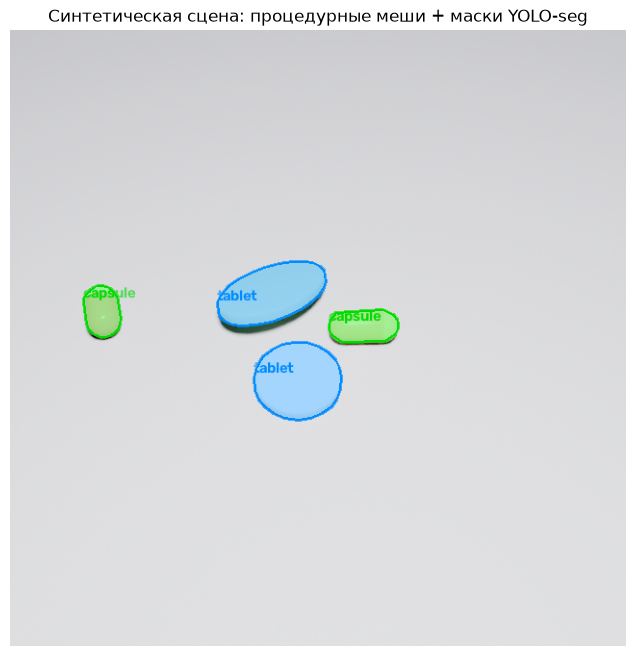

In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Запуск генератора через портативный Blender
!D:\Blender\blender.exe --background --python generator_blender.py

img_path = Path(r"D:\Tabmed\Tabmed_ml\synthetic_3d_output\images\synth_0001.png")
lbl_seg_path = Path(r"D:\Tabmed\Tabmed_ml\synthetic_3d_output\labels_seg\synth_0001.txt")

if img_path.exists() and lbl_seg_path.exists():
    img = cv2.imread(str(img_path))
    overlay = img.copy()
    h, w = img.shape[:2]

    # Схема Tabmed: 0 = capsule (зеленый), 1 = tablet (синий)
    colors = {0: (0, 220, 0), 1: (255, 140, 0)}
    names = {0: "capsule", 1: "tablet"}

    with open(lbl_seg_path, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) >= 7:
                cls_id = int(parts[0])
                coords = list(map(float, parts[1:]))

                # Восстанавливаем точки полигона в пикселях
                pts = []
                for i in range(0, len(coords), 2):
                    px = int(coords[i] * w)
                    py = int(coords[i + 1] * h)
                    pts.append([px, py])
                pts_np = np.array(pts, dtype=np.int32).reshape((-1, 1, 2))

                color = colors.get(cls_id, (0, 255, 255))
                # Полупрозрачная маска сегментации
                cv2.fillPoly(overlay, [pts_np], color)
                # Четкий контур
                cv2.polylines(img, [pts_np], isClosed=True, color=color, thickness=2)

                # Текстовая метка
                x_text, y_text = pts[0]
                cv2.putText(img, names.get(cls_id, ""), (x_text, max(15, y_text - 5)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)

    # Альфа-блендинг (прозрачность маски 35%)
    alpha = 0.35
    result_img = cv2.addWeighted(overlay, alpha, img, 1 - alpha, 0)

    plt.figure(figsize=(8, 8))
    plt.imshow(cv2.cvtColor(result_img, cv2.COLOR_BGR2RGB))
    plt.title("Синтетическая сцена: процедурные меши + маски YOLO-seg")
    plt.axis("off")
    plt.show()
else:
    print("Ошибка: файлы генерации не найдены.")

In [24]:
%%writefile batch_generator.py
import bpy
import math
import random
import sys
import json
from pathlib import Path
from mathutils import Vector

# ==========================================
# 1. Палитра эмиссионных цветов для ID-пасса
# ==========================================
ID_PALETTE_RGB = [
    (1.0, 0.0, 0.0),    # 0: Красный
    (0.0, 1.0, 0.0),    # 1: Зеленый
    (0.0, 0.0, 1.0),    # 2: Синий
    (1.0, 1.0, 0.0),    # 3: Желтый
    (1.0, 0.0, 1.0),    # 4: Пурпурный
    (0.0, 1.0, 1.0),    # 5: Голубой
    (1.0, 0.5, 0.0),    # 6: Оранжевый
    (0.5, 0.0, 1.0),    # 7: Фиолетовый
    (0.0, 0.5, 1.0),    # 8: Лазурный
    (0.5, 1.0, 0.0),    # 9: Лайм
    (1.0, 0.0, 0.5),    # 10: Розовый
    (0.0, 1.0, 0.5),    # 11: Мятный
]

PHARMA_PALETTE = {
    "white": (0.93, 0.93, 0.93),
    "chalk_white": (0.87, 0.86, 0.82),
    "yellow": (0.95, 0.82, 0.12),
    "blue": (0.08, 0.35, 0.85),
    "red": (0.85, 0.12, 0.12),
    "green": (0.12, 0.65, 0.25),
    "orange": (0.95, 0.45, 0.05),
    "pink": (0.92, 0.45, 0.55)
}

# ==========================================
# 2. Шейдеры материалов
# ==========================================
def create_table_material():
    mat = bpy.data.materials.new(name="Surface_Mat")
    mat.use_nodes = True
    nodes = mat.node_tree.nodes
    links = mat.node_tree.links
    bsdf = nodes.get("Principled BSDF")

    surface_types = ["dark", "light", "wood_tint", "skin_tint"]
    choice = random.choice(surface_types)

    if choice == "dark":
        base_col = (random.uniform(0.08, 0.18), random.uniform(0.08, 0.18), random.uniform(0.09, 0.20), 1.0)
        rough = random.uniform(0.6, 0.85)
    elif choice == "light":
        base_col = (random.uniform(0.75, 0.90), random.uniform(0.75, 0.90), random.uniform(0.75, 0.90), 1.0)
        rough = random.uniform(0.3, 0.6)
    elif choice == "skin_tint":
        base_col = (random.uniform(0.70, 0.85), random.uniform(0.50, 0.65), random.uniform(0.40, 0.55), 1.0)
        rough = random.uniform(0.5, 0.7)
    else:
        base_col = (random.uniform(0.25, 0.40), random.uniform(0.18, 0.28), random.uniform(0.12, 0.20), 1.0)
        rough = random.uniform(0.4, 0.7)

    tex_noise = nodes.new(type="ShaderNodeTexNoise")
    tex_noise.inputs['Scale'].default_value = random.uniform(150.0, 300.0)
    tex_noise.inputs['Detail'].default_value = 4.0
    
    color_ramp = nodes.new(type="ShaderNodeValToRGB")
    color_ramp.color_ramp.elements[0].color = (base_col[0]*0.9, base_col[1]*0.9, base_col[2]*0.9, 1.0)
    color_ramp.color_ramp.elements[1].color = base_col
    
    links.new(tex_noise.outputs['Fac'], color_ramp.inputs['Fac'])
    links.new(color_ramp.outputs['Color'], bsdf.inputs['Base Color'])
    bsdf.inputs['Roughness'].default_value = rough
    return mat

def get_chalk_mat(name, color_rgb):
    mat = bpy.data.materials.new(name=name)
    mat.use_nodes = True
    bsdf = mat.node_tree.nodes.get("Principled BSDF")
    bsdf.inputs['Base Color'].default_value = (*color_rgb, 1.0)
    bsdf.inputs['Roughness'].default_value = random.uniform(0.60, 0.85)
    if 'Subsurface Weight' in bsdf.inputs:
        bsdf.inputs['Subsurface Weight'].default_value = 0.08
    return mat

def get_gelatin_mat(name, color_rgb):
    mat = bpy.data.materials.new(name=name)
    mat.use_nodes = True
    bsdf = mat.node_tree.nodes.get("Principled BSDF")
    bsdf.inputs['Base Color'].default_value = (*color_rgb, 1.0)
    bsdf.inputs['Roughness'].default_value = random.uniform(0.08, 0.18)
    bsdf.inputs['IOR'].default_value = 1.48
    if 'Coat Weight' in bsdf.inputs:
        bsdf.inputs['Coat Weight'].default_value = 1.0
        bsdf.inputs['Coat Roughness'].default_value = 0.04
    return mat

# ==========================================
# 3. Фабрика процедурных мешей
# ==========================================
def spawn_round_tablet(loc, rot, has_score=False):
    radius = random.uniform(0.008, 0.012)
    depth = random.uniform(0.0035, 0.006)
    bpy.ops.mesh.primitive_cylinder_add(vertices=64, radius=radius, depth=depth, location=loc, rotation=rot)
    obj = bpy.context.active_object
    
    if has_score:
        bpy.ops.mesh.primitive_cube_add(size=1.0, location=(loc[0], loc[1], loc[2] + depth*0.48), rotation=rot)
        cutter = bpy.context.active_object
        cutter.scale = (radius * 2.2, 0.0006, depth * 0.3)
        bool_m = obj.modifiers.new(name="Cut", type='BOOLEAN')
        bool_m.operation = 'DIFFERENCE'
        bool_m.object = cutter
        bpy.context.view_layer.objects.active = obj
        bpy.ops.object.modifier_apply(modifier="Cut")
        bpy.data.objects.remove(cutter, do_unlink=True)

    bev = obj.modifiers.new(name="Bevel", type='BEVEL')
    bev.width = 0.0008
    bev.segments = 3
    bpy.ops.object.modifier_apply(modifier="Bevel")
    bpy.ops.object.shade_smooth()

    col = PHARMA_PALETTE[random.choice(["white", "chalk_white", "yellow", "pink", "green"])]
    obj.data.materials.append(get_chalk_mat("Tab_Mat", col))
    return obj

def spawn_oval_tablet(loc, rot):
    obj = spawn_round_tablet(loc, rot, has_score=False)
    obj.scale = (random.uniform(1.4, 1.7), 1.0, 1.0)
    bpy.context.view_layer.objects.active = obj
    bpy.ops.object.transform_apply(scale=True)
    return obj

def spawn_capsule(loc, rot):
    radius = random.uniform(0.0042, 0.0055)
    depth = random.uniform(0.015, 0.021)
    bpy.ops.mesh.primitive_cylinder_add(vertices=48, radius=radius, depth=depth, location=loc, rotation=rot)
    obj = bpy.context.active_object

    bev = obj.modifiers.new(name="CapBevel", type='BEVEL')
    bev.width = radius * 0.95
    bev.segments = 8
    bpy.ops.object.modifier_apply(modifier="CapBevel")
    bpy.ops.object.shade_smooth()

    col1 = random.choice(["blue", "red", "green", "orange", "yellow"])
    col2 = random.choice(["white", "yellow", "orange"])
    obj.data.materials.append(get_gelatin_mat("Top", PHARMA_PALETTE[col1]))
    obj.data.materials.append(get_gelatin_mat("Bot", PHARMA_PALETTE[col2]))

    for p in obj.data.polygons:
        p.material_index = 0 if p.center.z >= 0 else 1
    return obj

# ==========================================
# 4. Рендер одной сцены (Cycles Beauty + ID Mask)
# ==========================================
def render_single_scene(output_img_path):
    bpy.ops.wm.read_factory_settings(use_empty=True)
    scene = bpy.context.scene

    scene.render.engine = 'CYCLES'
    cycles = scene.cycles
    cycles.device = 'GPU'
    cycles.samples = 32
    cycles.preview_samples = 16
    cycles.use_denoising = True

    prefs = bpy.context.preferences.addons['cycles'].preferences
    prefs.compute_device_type = 'OPTIX'
    prefs.get_devices()
    for dev in prefs.devices:
        if dev.type == 'OPTIX':
            dev.use = True

    if not scene.rigidbody_world:
        bpy.ops.rigidbody.world_add()
    rbw = scene.rigidbody_world
    rbw.substeps_per_frame = 25
    rbw.solver_iterations = 40

    # Стол
    bpy.ops.mesh.primitive_cube_add(size=1.0, location=(0, 0, -0.05))
    table = bpy.context.active_object
    table.name = "Table"
    table.scale = (2.0, 2.0, 0.1)
    bpy.ops.rigidbody.object_add()
    table.rigid_body.type = 'PASSIVE'
    table.rigid_body.collision_shape = 'BOX'
    table.rigid_body.friction = random.uniform(0.75, 0.95)
    table.data.materials.append(create_table_material())

    # Спавн таблеток (от 3 до 8 шт)
    pills = []
    n_pills = random.randint(3, 8)
    types = ['round', 'round_score', 'oval', 'capsule', 'capsule']

    for i in range(n_pills):
        t = random.choice(types)
        loc = (random.uniform(-0.02, 0.02), random.uniform(-0.02, 0.02), 0.025 + i * 0.016)
        rot = (random.uniform(0, 3.14), random.uniform(0, 3.14), random.uniform(0, 3.14))

        if t == 'round':
            obj = spawn_round_tablet(loc, rot, has_score=False)
            cls_id = 1
        elif t == 'round_score':
            obj = spawn_round_tablet(loc, rot, has_score=True)
            cls_id = 1
        elif t == 'oval':
            obj = spawn_oval_tablet(loc, rot)
            cls_id = 1
        else:
            obj = spawn_capsule(loc, rot)
            cls_id = 0

        bpy.ops.rigidbody.object_add()
        obj.rigid_body.type = 'ACTIVE'
        obj.rigid_body.collision_shape = 'CONVEX_HULL'
        obj.rigid_body.mass = 0.003
        obj.rigid_body.friction = 0.75
        obj.rigid_body.linear_damping = 0.65
        obj.rigid_body.angular_damping = 0.65
        pills.append((obj, cls_id))

    # Симуляция падения
    for frame in range(1, 70):
        scene.frame_set(frame)

    deps = bpy.context.evaluated_depsgraph_get()
    for obj, _ in pills:
        eval_obj = obj.evaluated_get(deps)
        obj.matrix_world = eval_obj.matrix_world.copy()
        obj.rigid_body.enabled = False

    scene.frame_set(1)
    bpy.context.view_layer.update()

    # Освещение
    light_data = bpy.data.lights.new(name="Light", type='POINT')
    light_data.energy = random.uniform(50.0, 85.0)
    light_data.shadow_soft_size = random.uniform(0.02, 0.05)
    light_obj = bpy.data.objects.new(name="Light", object_data=light_data)
    scene.collection.objects.link(light_obj)
    light_obj.location = (random.uniform(-0.15, 0.15), random.uniform(-0.18, -0.05), random.uniform(0.25, 0.40))

    # Камера
    cam_data = bpy.data.cameras.new(name="Camera")
    cam_data.lens = random.uniform(45, 58)
    cam_obj = bpy.data.objects.new(name="Camera", object_data=cam_data)
    scene.collection.objects.link(cam_obj)
    scene.camera = cam_obj

    dist = random.uniform(0.18, 0.27)
    pitch = random.uniform(math.radians(18), math.radians(75))
    cam_z = dist * math.sin(pitch)
    cam_y = -dist * math.cos(pitch)
    cam_x = random.uniform(-0.05, 0.05)
    cam_obj.location = (cam_x, cam_y, cam_z)

    target = bpy.data.objects.new("Target", None)
    scene.collection.objects.link(target)
    target.location = (0, 0, 0.005)

    track = cam_obj.constraints.new(type='TRACK_TO')
    track.target = target
    track.track_axis = 'TRACK_NEGATIVE_Z'
    track.up_axis = 'UP_Y'

    bpy.context.view_layer.update()
    scene.render.resolution_x = 640
    scene.render.resolution_y = 640

    # 1. Beauty Pass (JPEG)
    scene.render.image_settings.file_format = 'JPEG'
    scene.render.image_settings.quality = 95
    scene.render.use_file_extension = False
    scene.render.filepath = str(output_img_path)
    bpy.ops.render.render(write_still=True)

    # 2. ID Mask Pass (Эмиссионные цвета без теней)
    light_obj.hide_render = True
    if scene.world and scene.world.node_tree:
        bg_node = scene.world.node_tree.nodes.get("Background")
        if bg_node:
            bg_node.inputs['Strength'].default_value = 0.0

    mat_black = bpy.data.materials.new(name="ID_Black")
    mat_black.use_nodes = True
    mat_black.node_tree.nodes.clear()
    emit_b = mat_black.node_tree.nodes.new(type='ShaderNodeEmission')
    emit_b.inputs['Color'].default_value = (0, 0, 0, 1)
    out_b = mat_black.node_tree.nodes.new(type='ShaderNodeOutputMaterial')
    mat_black.node_tree.links.new(emit_b.outputs['Emission'], out_b.inputs['Surface'])
    table.data.materials.clear()
    table.data.materials.append(mat_black)

    metadata = []
    for idx, (obj, cls_id) in enumerate(pills):
        col_rgb = ID_PALETTE_RGB[idx % len(ID_PALETTE_RGB)]
        mat_id = bpy.data.materials.new(name=f"ID_Mat_{idx}")
        mat_id.use_nodes = True
        mat_id.node_tree.nodes.clear()
        emit = mat_id.node_tree.nodes.new(type='ShaderNodeEmission')
        emit.inputs['Color'].default_value = (*col_rgb, 1.0)
        emit.inputs['Strength'].default_value = 1.0
        out_n = mat_id.node_tree.nodes.new(type='ShaderNodeOutputMaterial')
        mat_id.node_tree.links.new(emit.outputs['Emission'], out_n.inputs['Surface'])
        obj.data.materials.clear()
        obj.data.materials.append(mat_id)

        metadata.append({
            "class_id": cls_id,
            "color_rgb": [int(round(c * 255)) for c in col_rgb]
        })

    cycles.samples = 1
    cycles.preview_samples = 1
    cycles.use_denoising = False
    cycles.max_bounces = 0
    cycles.diffuse_bounces = 0
    cycles.glossy_bounces = 0
    cycles.transmission_bounces = 0

    try:
        scene.view_settings.view_transform = 'Raw'
    except Exception:
        scene.view_settings.view_transform = 'Standard'

    mask_path = output_img_path.with_name(f"{output_img_path.stem}_mask.png")
    meta_path = output_img_path.with_name(f"{output_img_path.stem}_meta.json")

    scene.render.image_settings.file_format = 'PNG'
    scene.render.filepath = str(mask_path)
    bpy.ops.render.render(write_still=True)

    with open(meta_path, "w", encoding="utf-8") as mf:
        json.dump(metadata, mf)

# ==========================================
# 5. CLI Точка входа
# ==========================================
if __name__ == "__main__":
    args = sys.argv
    count = 10
    if "--" in args:
        idx = args.index("--")
        if len(args) > idx + 1:
            count = int(args[idx + 1])

    root_dir = Path(r"D:\Tabmed\Tabmed_ml\synthetic_dataset")
    val_count = max(1, int(count * 0.2))
    train_count = count - val_count
    splits = [("train", train_count), ("val", val_count)]
    current_idx = 1

    for split_name, total in splits:
        img_dir = root_dir / "images" / split_name
        img_dir.mkdir(parents=True, exist_ok=True)

        for _ in range(total):
            img_file = img_dir / f"synth_{current_idx:06d}.jpg"
            render_single_scene(img_file)
            print(f"[{split_name.upper()} {current_idx}/{count}] Отрендерен: {img_file.name}")
            current_idx += 1

    print(f"\n[УСПЕХ] Рендер сцен в Blender завершен.")

Overwriting batch_generator.py


In [ ]:
import json
import cv2
import numpy as np
from pathlib import Path

# 1. Запуск рендера 15 сцен через Blender
!D:\Blender\blender.exe --background --python batch_generator.py -- 15

# 2. Обработка ID-масок силами Python venv блокнота
root_dir = Path(r"D:\Tabmed\Tabmed_ml\synthetic_dataset")

for split in ["train", "val"]:
    img_dir = root_dir / "images" / split
    lbl_dir = root_dir / "labels" / split
    lbl_dir.mkdir(parents=True, exist_ok=True)

    for meta_file in img_dir.glob("*_meta.json"):
        stem = meta_file.name.replace("_meta.json", "")
        mask_file = img_dir / f"{stem}_mask.png"
        lbl_file = lbl_dir / f"{stem}.txt"

        if not mask_file.exists():
            continue

        mask_bgr = cv2.imread(str(mask_file))
        if mask_bgr is None:
            continue
        h_m, w_m = mask_bgr.shape[:2]

        with open(meta_file, "r", encoding="utf-8") as mf:
            metadata = json.load(mf)

        seg_lines = []
        for item in metadata:
            cls_id = item["class_id"]
            r_t, g_t, b_t = item["color_rgb"]

            target = np.array([b_t, g_t, r_t], dtype=np.int16)
            dist_map = np.sum(np.abs(mask_bgr.astype(np.int16) - target), axis=-1)
            binary_mask = (dist_map < 40).astype(np.uint8) * 255

            contours, _ = cv2.findContours(binary_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            valid = [c for c in contours if cv2.contourArea(c) >= 35]

            # Если таблетка полностью перекрыта другой — пропускаем
            if not valid:
                continue

            largest = max(valid, key=cv2.contourArea)
            peri = cv2.arcLength(largest, True)
            approx = cv2.approxPolyDP(largest, max(0.8, 0.003 * peri), True)

            if len(approx) < 4:
                continue

            poly_coords = []
            for pt in approx.reshape(-1, 2):
                nx = max(0.0, min(1.0, pt[0] / w_m))
                ny = max(0.0, min(1.0, pt[1] / h_m))
                poly_coords.extend([round(nx, 6), round(ny, 6)])

            xs = poly_coords[0::2]
            ys = poly_coords[1::2]
            if (max(xs) - min(xs)) < 0.015 or (max(ys) - min(ys)) < 0.015:
                continue

            poly_str = " ".join(f"{c:.6f}" for c in poly_coords)
            seg_lines.append(f"{cls_id} {poly_str}")

        with open(lbl_file, "w", encoding="utf-8") as lf:
            lf.write("\n".join(seg_lines) + "\n")

        # Удаляем временные маски и JSON, оставляя только готовые jpg и txt
        mask_file.unlink(missing_ok=True)
        meta_file.unlink(missing_ok=True)

# 3. Запись актуального data.yaml
yaml_content = f"""path: {root_dir.as_posix()}
train: images/train
val: images/val

names:
  0: capsule
  1: tablet
"""
with open(root_dir / "data.yaml", "w", encoding="utf-8") as yf:
    yf.write(yaml_content)

print(f"\n[ГОТОВО] Все маски извлечены в полигоны YOLO-seg. Конфиг сохранен в: {root_dir / 'data.yaml'}")

^C

[ГОТОВО] Все маски извлечены в полигоны YOLO-seg. Конфиг сохранен в: D:\Tabmed\Tabmed_ml\synthetic_dataset\data.yaml


Blender 4.2.1 LTS (hash 396f546c9d82 built 2024-08-19 11:29:52)
Fra:1 Mem:12.95M (Peak 12.95M) | Time:00:00.18 | Mem:0.00M, Peak:0.00M | Scene, ViewLayer | Synchronizing object | Table
Fra:1 Mem:12.95M (Peak 12.95M) | Time:00:00.18 | Mem:0.00M, Peak:0.00M | Scene, ViewLayer | Synchronizing object | Cylinder.003
Fra:1 Mem:12.95M (Peak 12.95M) | Time:00:00.18 | Mem:0.00M, Peak:0.00M | Scene, ViewLayer | Synchronizing object | Cylinder.006
Fra:1 Mem:13.68M (Peak 13.68M) | Time:00:00.18 | Mem:0.00M, Peak:0.00M | Scene, ViewLayer | Initializing
Fra:1 Mem:12.80M (Peak 13.68M) | Time:00:00.18 | Mem:0.00M, Peak:0.00M | Scene, ViewLayer | Waiting for render to start
Fra:1 Mem:12.81M (Peak 13.68M) | Time:00:00.18 | Mem:0.00M, Peak:0.00M | Scene, ViewLayer | Loading render kernels (may take a few minutes the first time)
Fra:1 Mem:12.81M (Peak 41.18M) | Time:00:00.26 | Mem:0.01M, Peak:0.01M | Scene, ViewLayer | Updating Scene
Fra:1 Mem:12.81M (Peak 41.18M) | Time:00:00.26 | Mem:0.01M, Peak:0.01M |

Найдено снимков в train: 12


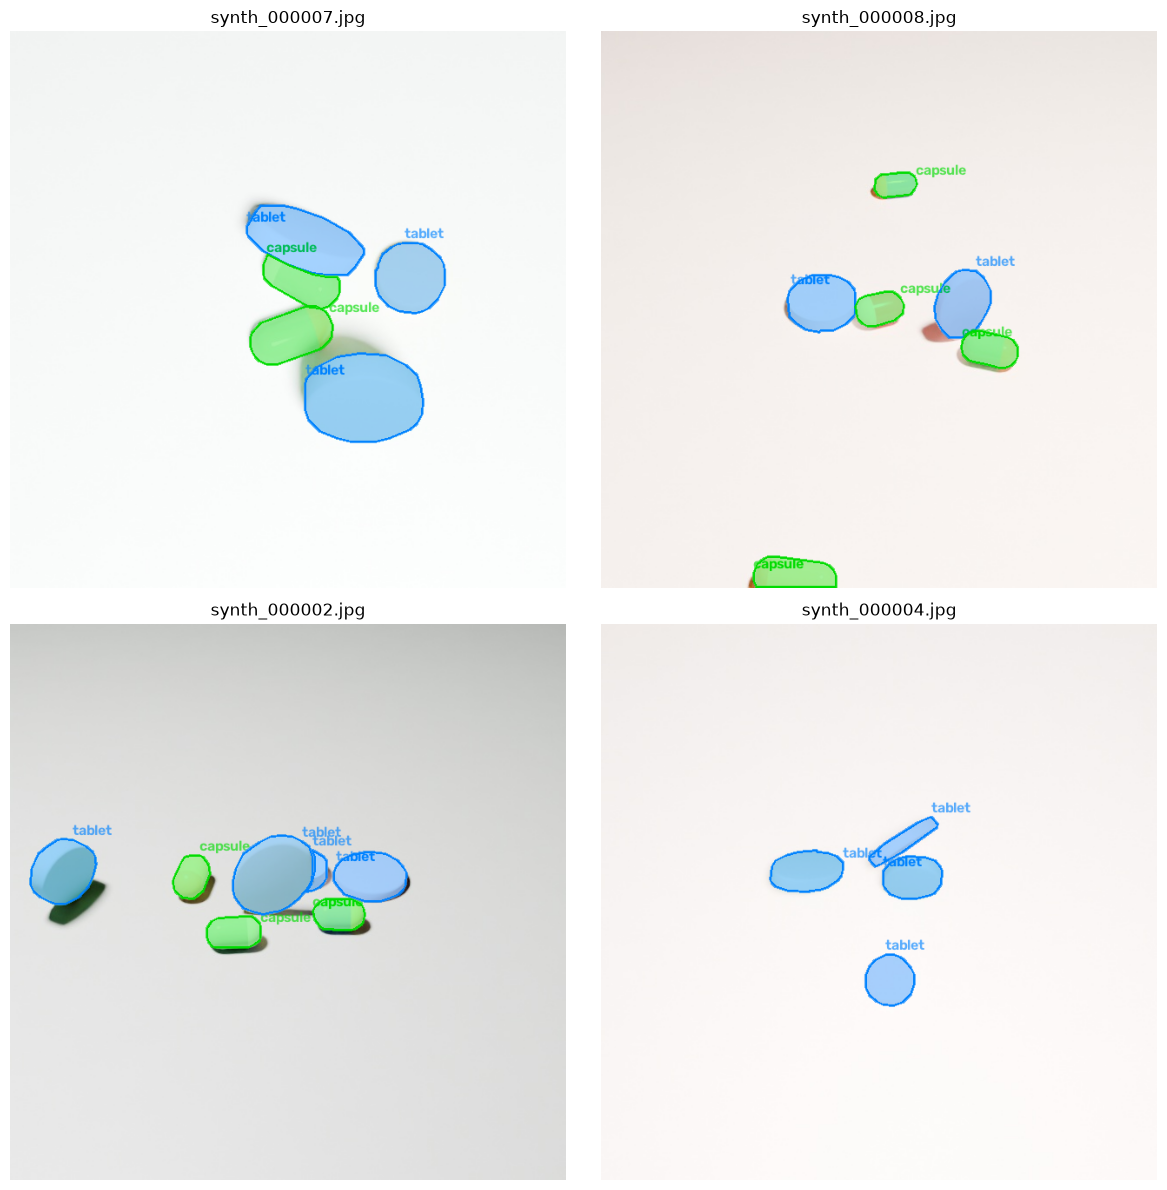

In [26]:
import cv2
import random
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

train_img_dir = Path(r"D:\Tabmed\Tabmed_ml\synthetic_dataset\images\train")
train_lbl_dir = Path(r"D:\Tabmed\Tabmed_ml\synthetic_dataset\labels\train")

all_imgs = list(train_img_dir.glob("*.jpg"))
print(f"Найдено снимков в train: {len(all_imgs)}")

if all_imgs:
    sample_imgs = random.sample(all_imgs, min(4, len(all_imgs)))
    fig, axes = plt.subplots(2, 2, figsize=(12, 12))
    axes = axes.flatten()

    colors = {0: (0, 220, 0), 1: (255, 130, 0)}  # 0: capsule, 1: tablet
    names = {0: "capsule", 1: "tablet"}

    for idx, img_p in enumerate(sample_imgs):
        img = cv2.imread(str(img_p))
        overlay = img.copy()
        h, w = img.shape[:2]

        lbl_p = train_lbl_dir / f"{img_p.stem}.txt"
        if lbl_p.exists():
            with open(lbl_p, "r", encoding="utf-8") as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) >= 7:
                        cls_id = int(parts[0])
                        coords = list(map(float, parts[1:]))
                        pts = [[int(coords[i]*w), int(coords[i+1]*h)] for i in range(0, len(coords), 2)]
                        pts_np = np.array(pts, dtype=np.int32).reshape((-1, 1, 2))
                        
                        col = colors.get(cls_id, (0, 255, 255))
                        cv2.fillPoly(overlay, [pts_np], col)
                        cv2.polylines(img, [pts_np], True, col, 2)
                        
                        x_t, y_t = pts[0]
                        cv2.putText(img, names.get(cls_id, ""), (x_t, max(18, y_t - 5)),
                                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, col, 2)

        blended = cv2.addWeighted(overlay, 0.35, img, 0.65, 0)
        axes[idx].imshow(cv2.cvtColor(blended, cv2.COLOR_BGR2RGB))
        axes[idx].set_title(img_p.name, fontsize=12)
        axes[idx].axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Изображения не найдены.")

# Масштабная генерация

In [27]:
import time
import shutil
from pathlib import Path

DATASET_ROOT = Path(r"D:\Tabmed\Tabmed_ml\synthetic_dataset")

# 1. Очистка старой тестовой выборки перед финальной генерацией
if DATASET_ROOT.exists():
    shutil.rmtree(DATASET_ROOT)
DATASET_ROOT.mkdir(parents=True, exist_ok=True)

TARGET_FRAMES = 300
print(f"Запуск генерации целевого датасета: {TARGET_FRAMES} сцен...")
start_time = time.time()

# 2. Рендер геометрии и масок в Blender (OptiX Cycles)
!D:\Blender\blender.exe --background --python batch_generator.py -- {TARGET_FRAMES}

# 3. Извлечение честных Modal-масок через OpenCV
for split in ["train", "val"]:
    img_dir = DATASET_ROOT / "images" / split
    lbl_dir = DATASET_ROOT / "labels" / split
    lbl_dir.mkdir(parents=True, exist_ok=True)

    meta_files = list(img_dir.glob("*_meta.json"))
    for meta_file in meta_files:
        stem = meta_file.name.replace("_meta.json", "")
        mask_file = img_dir / f"{stem}_mask.png"
        lbl_file = lbl_dir / f"{stem}.txt"

        if not mask_file.exists():
            continue

        mask_bgr = cv2.imread(str(mask_file))
        if mask_bgr is None:
            continue
        h_m, w_m = mask_bgr.shape[:2]

        with open(meta_file, "r", encoding="utf-8") as mf:
            metadata = json.load(mf)

        seg_lines = []
        for item in metadata:
            cls_id = item["class_id"]
            r_t, g_t, b_t = item["color_rgb"]

            target = np.array([b_t, g_t, r_t], dtype=np.int16)
            dist_map = np.sum(np.abs(mask_bgr.astype(np.int16) - target), axis=-1)
            binary_mask = (dist_map < 40).astype(np.uint8) * 255

            contours, _ = cv2.findContours(binary_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            valid = [c for c in contours if cv2.contourArea(c) >= 35]

            if not valid:
                continue

            largest = max(valid, key=cv2.contourArea)
            peri = cv2.arcLength(largest, True)
            approx = cv2.approxPolyDP(largest, max(0.8, 0.003 * peri), True)

            if len(approx) < 4:
                continue

            poly_coords = []
            for pt in approx.reshape(-1, 2):
                nx = max(0.0, min(1.0, pt[0] / w_m))
                ny = max(0.0, min(1.0, pt[1] / h_m))
                poly_coords.extend([round(nx, 6), round(ny, 6)])

            xs = poly_coords[0::2]
            ys = poly_coords[1::2]
            if (max(xs) - min(xs)) < 0.015 or (max(ys) - min(ys)) < 0.015:
                continue

            poly_str = " ".join(f"{c:.6f}" for c in poly_coords)
            seg_lines.append(f"{cls_id} {poly_str}")

        with open(lbl_file, "w", encoding="utf-8") as lf:
            lf.write("\n".join(seg_lines) + "\n")

        mask_file.unlink(missing_ok=True)
        meta_file.unlink(missing_ok=True)

# 4. Обновление data.yaml
yaml_content = f"""path: {DATASET_ROOT.as_posix()}
train: images/train
val: images/val

names:
  0: capsule
  1: tablet
"""
with open(DATASET_ROOT / "data.yaml", "w", encoding="utf-8") as yf:
    yf.write(yaml_content)

elapsed = time.time() - start_time
print(f"\n[ГОТОВО] Сгенерировано {TARGET_FRAMES} кадров за {elapsed/60:.1f} минут ({elapsed/TARGET_FRAMES:.2f} сек/кадр).")

Запуск генерации целевого датасета: 300 сцен...
Blender 4.2.1 LTS (hash 396f546c9d82 built 2024-08-19 11:29:52)
Fra:1 Mem:11.88M (Peak 11.88M) | Time:00:00.19 | Mem:0.00M, Peak:0.00M | Scene, ViewLayer | Synchronizing object | Table
Fra:1 Mem:11.88M (Peak 11.88M) | Time:00:00.19 | Mem:0.00M, Peak:0.00M | Scene, ViewLayer | Synchronizing object | Cylinder.003
Fra:1 Mem:12.29M (Peak 12.29M) | Time:00:00.19 | Mem:0.00M, Peak:0.00M | Scene, ViewLayer | Initializing
Fra:1 Mem:11.72M (Peak 12.29M) | Time:00:00.19 | Mem:0.00M, Peak:0.00M | Scene, ViewLayer | Waiting for render to start
Fra:1 Mem:11.72M (Peak 12.29M) | Time:00:00.19 | Mem:0.00M, Peak:0.00M | Scene, ViewLayer | Loading render kernels (may take a few minutes the first time)
Fra:1 Mem:11.72M (Peak 40.09M) | Time:00:00.28 | Mem:0.01M, Peak:0.01M | Scene, ViewLayer | Updating Scene
Fra:1 Mem:11.72M (Peak 40.09M) | Time:00:00.28 | Mem:0.01M, Peak:0.01M | Scene, ViewLayer | Updating Shaders
Fra:1 Mem:11.81M (Peak 40.09M) | Time:00:00

In [28]:
from collections import Counter
from pathlib import Path

DATASET_ROOT = Path(r"D:\Tabmed\Tabmed_ml\synthetic_dataset")

stats = {"train": Counter(), "val": Counter()}
class_names = {0: "capsule", 1: "tablet"}

for split in ["train", "val"]:
    lbl_files = list((DATASET_ROOT / "labels" / split).glob("*.txt"))
    for lf in lbl_files:
        with open(lf, "r", encoding="utf-8") as f:
            for line in f:
                parts = line.strip().split()
                if parts:
                    stats[split][int(parts[0])] += 1

print("=" * 45)
print(f"{'Сплит':<8} | {'Capsules (0)':<14} | {'Tablets (1)':<12} | {'Всего'}")
print("-" * 45)
for split in ["train", "val"]:
    caps = stats[split][0]
    tabs = stats[split][1]
    print(f"{split:<8} | {caps:<14} | {tabs:<12} | {caps + tabs}")
print("=" * 45)

Сплит    | Capsules (0)   | Tablets (1)  | Всего
---------------------------------------------
train    | 429            | 784          | 1213
val      | 94             | 188          | 282


# Бекап

In [29]:
import shutil
from pathlib import Path

BASE_DIR = Path(r"D:\Tabmed\Tabmed_ml")
CURRENT_BEST = BASE_DIR / "best.pt"
BACKUP_PATH = BASE_DIR / "best_pre_hybrid_backup.pt"

# Проверяем и сохраняем текущие лучшие веса
if CURRENT_BEST.is_file():
    shutil.copy2(CURRENT_BEST, BACKUP_PATH)
    print(f"[УСПЕХ] Контрольный бэкап сохранен: {BACKUP_PATH}")
else:
    # Если в корне файла не оказалось, ищем в последних прогонах segment
    runs_weights = list((BASE_DIR / "runs" / "segment").glob("**/weights/best.pt"))
    if runs_weights:
        latest = max(runs_weights, key=lambda p: p.stat().st_mtime)
        shutil.copy2(latest, BACKUP_PATH)
        print(f"[УСПЕХ] Найден и скопирован последний чекпоинт из runs: {BACKUP_PATH}")
    else:
        print("[ПРЕДУПРЕЖДЕНИЕ] Старый best.pt не найден. Будет использован базовый чекпоинт yolo26n-seg.pt.")

[УСПЕХ] Контрольный бэкап сохранен: D:\Tabmed\Tabmed_ml\best_pre_hybrid_backup.pt


In [30]:
import random
import shutil
from pathlib import Path

random.seed(42)

# Пути к источникам
REAL_DIR = Path(r"D:\Tabmed\Datasets\dataset_v7_seg_up")
if not REAL_DIR.exists():
    REAL_DIR = Path(r"D:\Tabmed\dataset_v7_seg_up")

SYNTH_DIR = Path(r"D:\Tabmed\Tabmed_ml\synthetic_dataset")
HYBRID_DIR = Path(r"D:\Tabmed\Datasets\dataset_hybrid_50synth")

# Создаем чистую структуру целевой папки
if HYBRID_DIR.exists():
    shutil.rmtree(HYBRID_DIR)

for split in ["train", "val"]:
    (HYBRID_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
    (HYBRID_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)

# 1. Переносим все 73 реальных кадра
real_total = 0
for split in ["train", "val"]:
    r_img_dir = REAL_DIR / "images" / split
    r_lbl_dir = REAL_DIR / "labels" / split
    if r_img_dir.exists():
        for img_p in r_img_dir.glob("*.*"):
            lbl_p = r_lbl_dir / f"{img_p.stem}.txt"
            if lbl_p.exists():
                shutil.copy2(img_p, HYBRID_DIR / "images" / split / f"real_{img_p.name}")
                shutil.copy2(lbl_p, HYBRID_DIR / "labels" / split / f"real_{img_p.stem}.txt")
                real_total += 1

# 2. Отбираем ровно 50 синтетических сцен (40 train / 10 val)
synth_train_imgs = list((SYNTH_DIR / "images" / "train").glob("*.jpg"))
synth_val_imgs = list((SYNTH_DIR / "images" / "val").glob("*.jpg"))

sample_synth_train = random.sample(synth_train_imgs, min(40, len(synth_train_imgs)))
sample_synth_val = random.sample(synth_val_imgs, min(10, len(synth_val_imgs)))

def copy_synth_sample(img_list, split):
    for img_p in img_list:
        lbl_p = SYNTH_DIR / "labels" / split / f"{img_p.stem}.txt"
        if lbl_p.exists():
            shutil.copy2(img_p, HYBRID_DIR / "images" / split / img_p.name)
            shutil.copy2(lbl_p, HYBRID_DIR / "labels" / split / lbl_p.name)

copy_synth_sample(sample_synth_train, "train")
copy_synth_sample(sample_synth_val, "val")

# 3. Фиксируем data.yaml
yaml_content = f"""path: {HYBRID_DIR.as_posix()}
train: images/train
val: images/val

names:
  0: capsule
  1: tablet
"""
with open(HYBRID_DIR / "data.yaml", "w", encoding="utf-8") as f:
    f.write(yaml_content)

train_count = len(list((HYBRID_DIR / "images" / "train").glob("*.*")))
val_count = len(list((HYBRID_DIR / "images" / "val").glob("*.*")))

print("=" * 50)
print(f"Сборка гибридного датасета завершена: {HYBRID_DIR}")
print(f"Реальных кадров: 73 (сохранены полностью)")
print(f"Синтетических 3D: 50 (40 train / 10 val)")
print(f"Итого в выборке: Train = {train_count}, Val = {val_count} (Всего: {train_count + val_count})")
print("=" * 50)

Сборка гибридного датасета завершена: D:\Tabmed\Datasets\dataset_hybrid_50synth
Реальных кадров: 73 (сохранены полностью)
Синтетических 3D: 50 (40 train / 10 val)
Итого в выборке: Train = 98, Val = 25 (Всего: 123)


In [31]:
from ultralytics import YOLO
from pathlib import Path

HYBRID_YAML = Path(r"D:\Tabmed\Datasets\dataset_hybrid_50synth\data.yaml")
PROJECT_DIR = Path(r"D:\Tabmed\Tabmed_ml\runs\segment")

# Используем локальный базовый чекпоинт из корня
model = YOLO("yolo26n-seg.pt")

print("Запуск обучения yolo26n-seg на гибридном наборе (RTX 4060 Ti)...")

results = model.train(
    data=str(HYBRID_YAML),
    epochs=50,
    patience=15,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    project=str(PROJECT_DIR),
    name="tabmed_hybrid_50synth_v1",
    exist_ok=True,
    # Аугментации для устранения границы между синтетикой и фото
    degrees=180.0,
    fliplr=0.5,
    flipud=0.5,
    scale=0.3,
    mosaic=1.0,
    hsv_h=0.015,
    hsv_s=0.4,
    hsv_v=0.3
)

print(f"\n[УСПЕХ] Обучение завершено. Итоговые веса сохранены в runs/segment/tabmed_hybrid_50synth_v1/weights/best.pt")

Запуск обучения yolo26n-seg на гибридном наборе (RTX 4060 Ti)...
New https://pypi.org/project/ultralytics/8.4.201 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.189  Python-3.12.0 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 4060 Ti, 16380MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\Tabmed\Datasets\dataset_hybrid_50synth\data.yaml, degrees=180.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.4, hsv_v=0.3, imgsz=640, iou=0.7, kobj=1.0, line_width

# Проверка

In [32]:
import pandas as pd
from pathlib import Path

exp_dir = Path(r"D:\Tabmed\Tabmed_ml\runs\segment\tabmed_hybrid_50synth_v1")
csv_path = exp_dir / "results.csv"

if csv_path.exists():
    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()
    
    # Находим эпоху с лучшим качеством масок
    best_row = df.loc[df['metrics/mAP50-95(M)'].idxmax()]
    
    print("=" * 65)
    print(f"ИТОГОВЫЕ МЕТРИКИ ГИБРИДНОЙ МОДЕЛИ (Лучшая эпоха: {int(best_row['epoch'])})")
    print("=" * 65)
    print(f"Box Detection: mAP50(B)    = {best_row['metrics/mAP50(B)']:.4f}  |  mAP50-95(B) = {best_row['metrics/mAP50-95(B)']:.4f}")
    print(f"Segmentation:  mAP50(M)    = {best_row['metrics/mAP50(M)']:.4f}  |  mAP50-95(M) = {best_row['metrics/mAP50-95(M)']:.4f}")
    print("=" * 65)
else:
    print(f"Файл {csv_path} не найден.")

ИТОГОВЫЕ МЕТРИКИ ГИБРИДНОЙ МОДЕЛИ (Лучшая эпоха: 40)
Box Detection: mAP50(B)    = 0.9623  |  mAP50-95(B) = 0.8128
Segmentation:  mAP50(M)    = 0.9444  |  mAP50-95(M) = 0.7539



image 1/1 D:\Tabmed\Tabmed_ml\test.jpg: 640x480 2 capsules, 36.5ms
Speed: 4.5ms preprocess, 36.5ms inference, 7.5ms postprocess per image at shape (1, 3, 640, 480)
Результат детекции на реальном кадре: test.jpg
Обнаружено объектов: 2
  • Объект 1: capsule | conf: 73.98%
  • Объект 2: capsule | conf: 68.65%


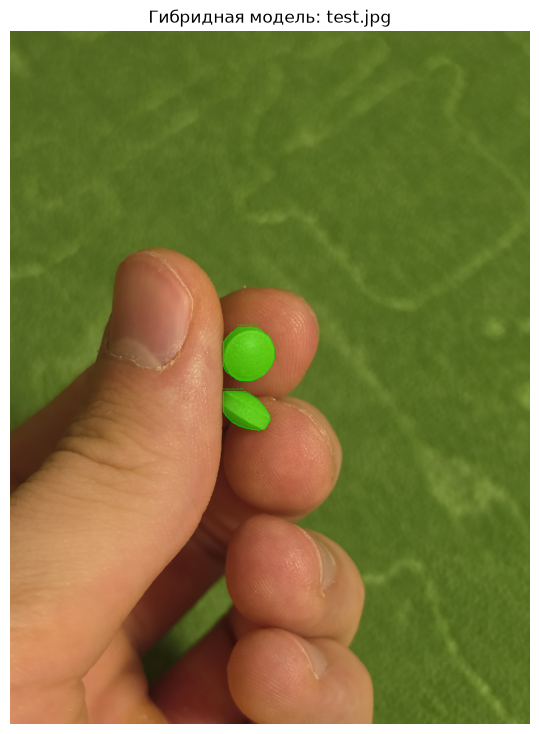

In [33]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO

HYBRID_WEIGHTS = Path(r"D:\Tabmed\Tabmed_ml\runs\segment\tabmed_hybrid_50synth_v1\weights\best.pt")
TEST_IMG = Path(r"D:\Tabmed\Tabmed_ml\test.jpg")

if HYBRID_WEIGHTS.exists() and TEST_IMG.exists():
    model = YOLO(str(HYBRID_WEIGHTS))
    results = model.predict(source=str(TEST_IMG), conf=0.30, imgsz=640, device=0)[0]

    img = cv2.imread(str(TEST_IMG))
    overlay = img.copy()
    h, w = img.shape[:2]

    # Схема классов Tabmed: 0 = capsule (зеленый), 1 = tablet (синий)
    colors = {0: (0, 220, 0), 1: (255, 140, 0)}
    names = {0: "capsule", 1: "tablet"}

    print("=" * 55)
    print(f"Результат детекции на реальном кадре: {TEST_IMG.name}")
    print(f"Обнаружено объектов: {len(results.boxes)}")

    if results.masks is not None:
        for idx, (box, seg) in enumerate(zip(results.boxes, results.masks.xy)):
            cls_id = int(box.cls[0].item())
            conf = float(box.conf[0].item())
            cls_name = names.get(cls_id, str(cls_id))

            print(f"  • Объект {idx+1}: {cls_name} | conf: {conf:.2%}")

            pts = np.array(seg, dtype=np.int32).reshape((-1, 1, 2))
            col = colors.get(cls_id, (0, 255, 255))
            cv2.fillPoly(overlay, [pts], col)
            cv2.polylines(img, [pts], isClosed=True, color=col, thickness=3)

            # Координата для текста над маской
            x_t, y_t = pts[0][0]
            cv2.putText(img, f"{cls_name} {conf:.2f}", (x_t, max(25, y_t - 8)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.65, col, 2)

    blended = cv2.addWeighted(overlay, 0.35, img, 0.65, 0)
    plt.figure(figsize=(9, 9))
    plt.imshow(cv2.cvtColor(blended, cv2.COLOR_BGR2RGB))
    plt.title(f"Гибридная модель: {TEST_IMG.name}")
    plt.axis("off")
    plt.show()
else:
    print("Ошибка: веса или test.jpg не найдены.")

Тестирование модели: best.pt
Отобрано реальных снимков: 16
№   | Файл                         | Capsules  | Tablets  | Всего  | Уверенность (avg)
--------------------------------------------------------------------------------
1   | v5_seblful_close-up-several  | 0         | 9        | 9      | 45.7%
2   | v5_20261024_001237.jpg       | 0         | 0        | 0      | -
3   | v5_IMG_20260202_111439.jpg   | 27        | 0        | 27     | 91.2%
4   | v5_IMG_20260202_111241.jpg   | 8         | 0        | 8      | 90.0%
5   | v5_IMG_20260202_111232.jpg   | 10        | 0        | 10     | 92.0%
6   | v5_20261024_001244.jpg       | 2         | 0        | 2      | 70.2%
7   | v5_seblful_3607706487_jpg.r  | 0         | 13       | 13     | 85.0%
8   | v5_IMG_20260202_111534.jpg   | 12        | 0        | 12     | 91.0%
9   | v5_seblful_1648033847_jpg.r  | 0         | 8        | 8      | 87.1%
10  | v5_IMG_20260202_111052.jpg   | 0         | 5        | 5      | 86.7%
11  | v5_20261024_001224.jp

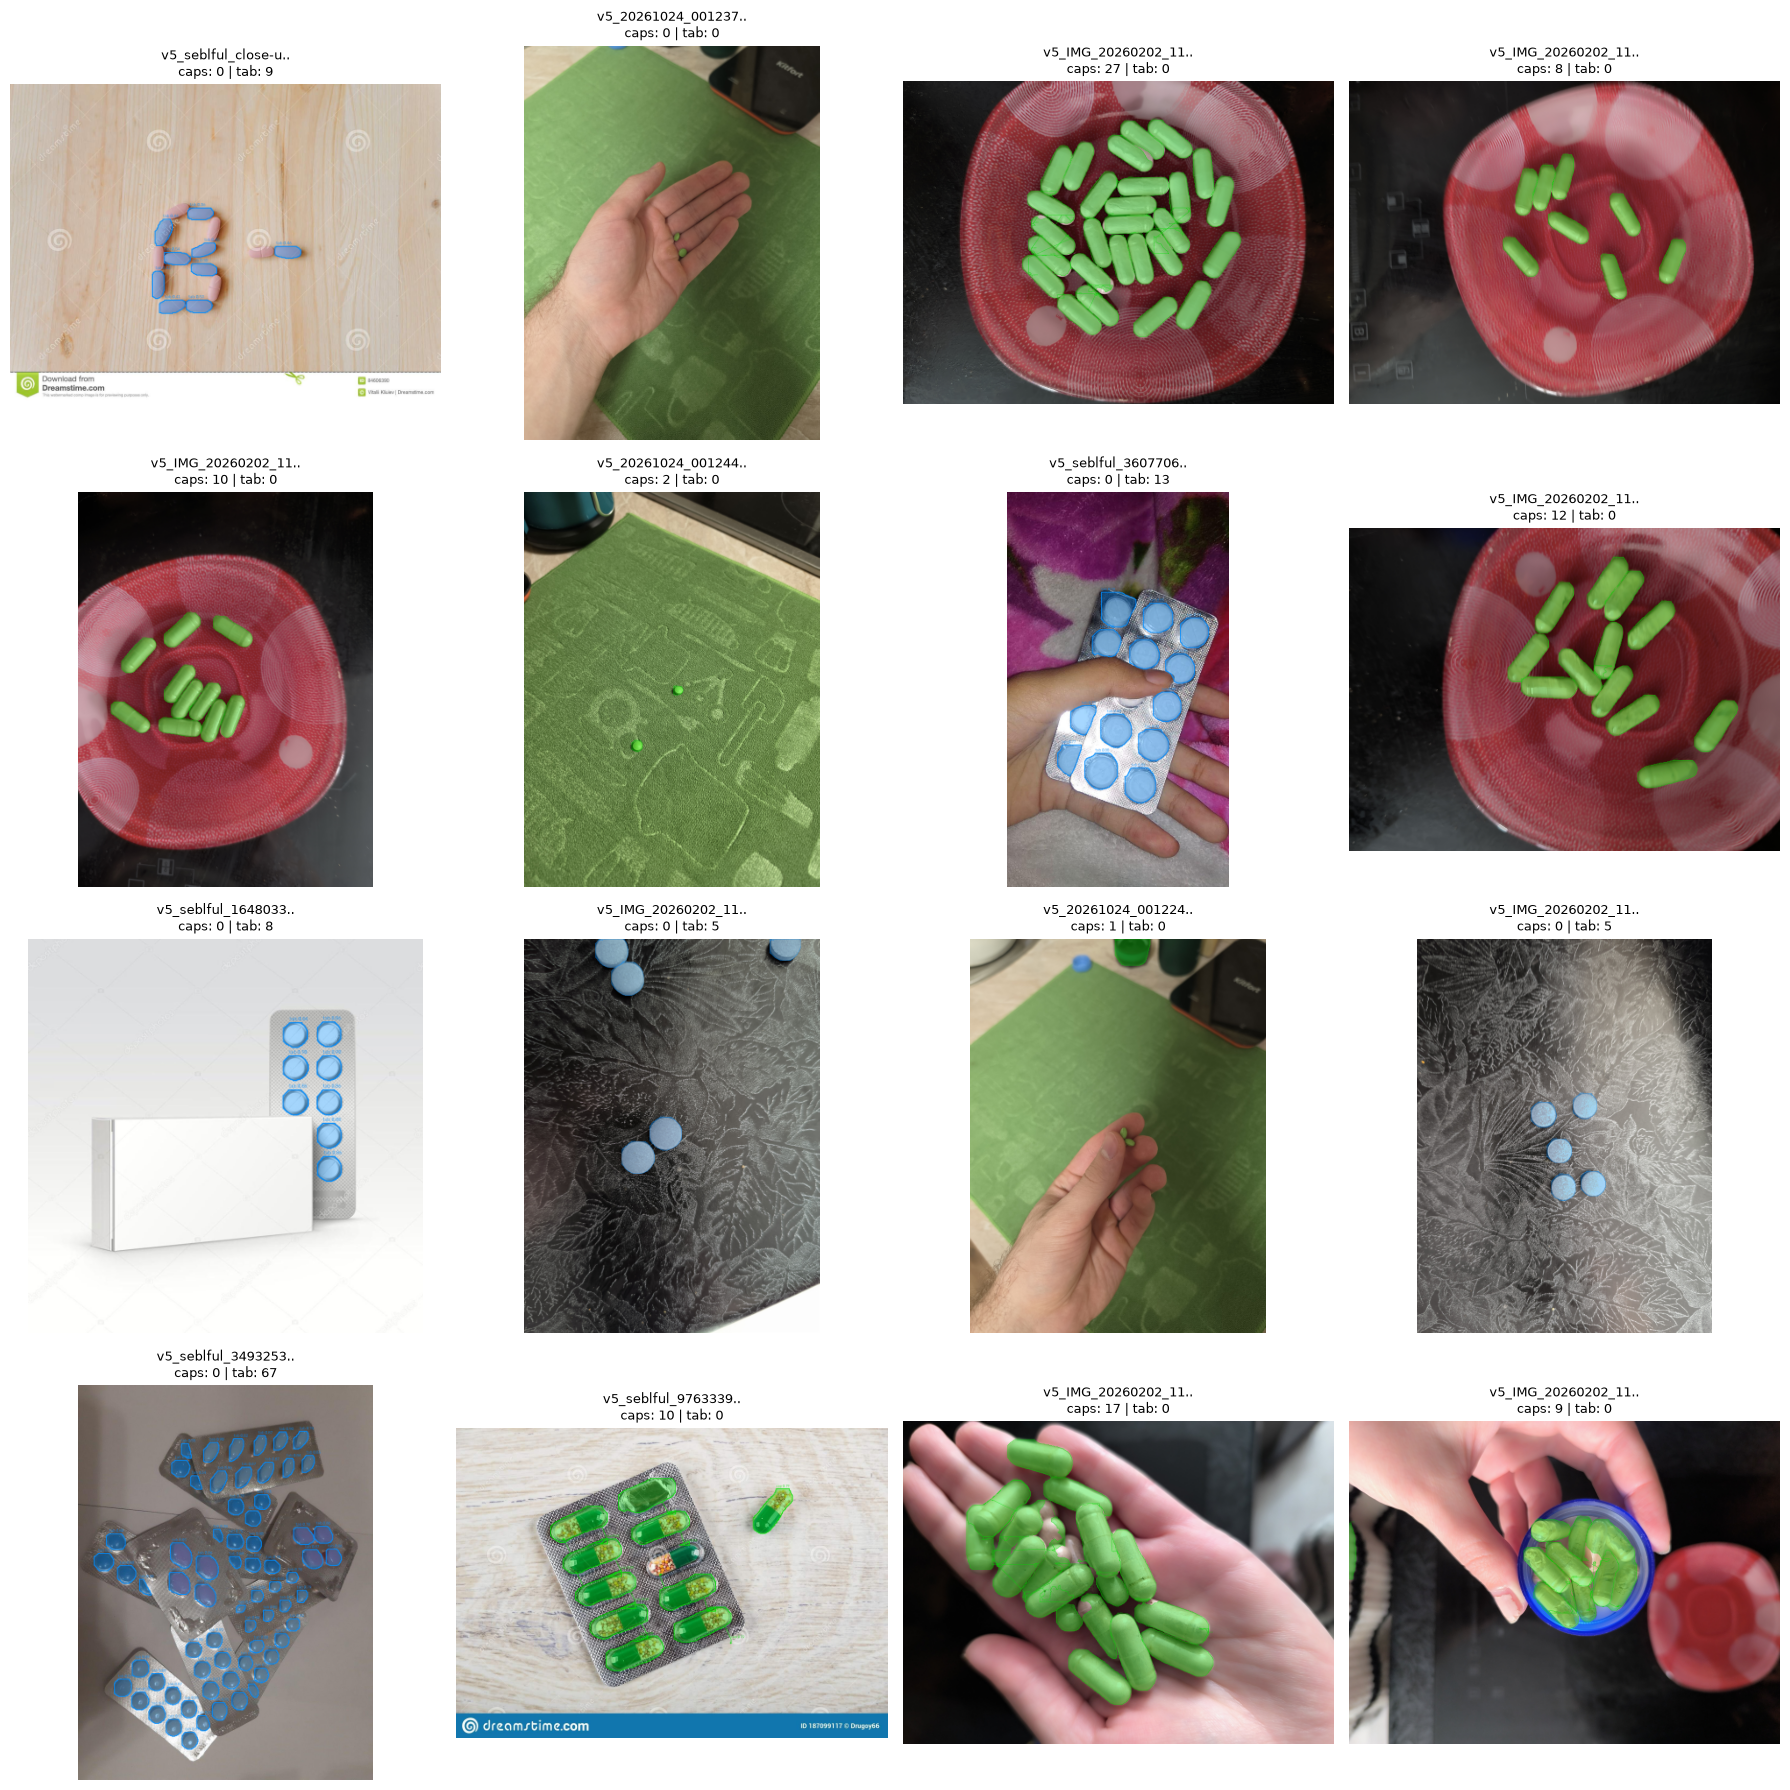

In [34]:
import random
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
from ultralytics import YOLO

# 1. Загрузка весов гибридной модели
WEIGHTS_PATH = Path(
    r"D:\Tabmed\Tabmed_ml\runs\segment\tabmed_hybrid_50synth_v1\weights\best.pt"
)
if not WEIGHTS_PATH.exists():
    WEIGHTS_PATH = Path(r"D:\Tabmed\Tabmed_ml\best.pt")

model = YOLO(str(WEIGHTS_PATH))

# 2. Сбор реальных тестовых фото
REAL_VAL_DIR = Path(r"D:\Tabmed\Datasets\dataset_v7_seg_up\images\val")
REAL_TRAIN_DIR = Path(r"D:\Tabmed\Datasets\dataset_v7_seg_up\images\train")
D1_DIR = Path(r"D:\Tabmed\dataset1\images")

# Приоритет валидационным снимкам + добор из train/dataset1 для разнообразия фонов
candidates = []
if REAL_VAL_DIR.exists():
    candidates += list(REAL_VAL_DIR.glob("*.*"))
if REAL_TRAIN_DIR.exists():
    candidates += list(REAL_TRAIN_DIR.glob("*.*"))
if D1_DIR.exists():
    candidates += list(D1_DIR.glob("*.*"))

# Исключаем дубликаты путей
candidates = list(dict.fromkeys(candidates))

# Фиксируем seed для воспроизводимости выборки из 16 фото
random.seed(42)
test_sample = random.sample(candidates, min(16, len(candidates)))

print(f"Тестирование модели: {WEIGHTS_PATH.name}")
print(f"Отобрано реальных снимков: {len(test_sample)}")
print("=" * 80)
print(
    f"{'№':<3} | {'Файл':<28} | {'Capsules':<9} | {'Tablets':<8} | {'Всего':<6} | {'Уверенность (avg)'}"
)
print("-" * 80)

# Цветовая схема: 0: capsule (зеленый), 1: tablet (синий)
colors = {0: (0, 220, 0), 1: (255, 140, 0)}
class_names = {0: "capsule", 1: "tablet"}

processed_cards = []

for idx, img_path in enumerate(test_sample, 1):
    orig = cv2.imread(str(img_path))
    if orig is None:
        continue
    h_orig, w_orig = orig.shape[:2]
    overlay = orig.copy()

    # Инференс с порогом 0.35
    res = model.predict(source=orig, conf=0.35, imgsz=640, verbose=False)[0]

    counts = {"capsule": 0, "tablet": 0}
    confs = []

    if res.masks is not None and res.boxes is not None:
        for box, seg in zip(res.boxes, res.masks.xy):
            cls_id = int(box.cls[0].item())
            conf_val = float(box.conf[0].item())

            c_name = class_names.get(cls_id, str(cls_id))
            counts[c_name] = counts.get(c_name, 0) + 1
            confs.append(conf_val)

            # Отрисовка маски
            pts = np.array(seg, dtype=np.int32).reshape((-1, 1, 2))
            col = colors.get(cls_id, (0, 255, 255))
            cv2.fillPoly(overlay, [pts], col)
            cv2.polylines(orig, [pts], isClosed=True, color=col, thickness=2)

            # Метка класса
            if len(pts) > 0:
                xt, yt = pts[0][0]
                cv2.putText(
                    orig,
                    f"{c_name[:3]} {conf_val:.2f}",
                    (xt, max(18, yt - 5)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.45,
                    col,
                    1,
                    cv2.LINE_AA,
                )

    blended = cv2.addWeighted(overlay, 0.35, orig, 0.65, 0)
    blended_rgb = cv2.cvtColor(blended, cv2.COLOR_BGR2RGB)

    # Масштабирование превью под 450px, чтобы не перегружать память VS Code
    scale = 450 / max(h_orig, w_orig)
    preview = cv2.resize(
        blended_rgb,
        (int(w_orig * scale), int(h_orig * scale)),
        interpolation=cv2.INTER_AREA,
    )

    tot = counts["capsule"] + counts["tablet"]
    avg_conf = f"{np.mean(confs):.1%}" if confs else "-"

    print(
        f"{idx:<3} | {img_path.name[:27]:<28} | {counts['capsule']:<9} | {counts['tablet']:<8} | {tot:<6} | {avg_conf}"
    )
    processed_cards.append((img_path.name, preview, counts))

print("=" * 80)

# 3. Отрисовка сетки 4x4
fig, axes = plt.subplots(4, 4, figsize=(18, 18))
axes = axes.flatten()

for i, (fname, img_view, counts) in enumerate(processed_cards):
    axes[i].imshow(img_view)
    axes[i].set_title(
        f"{fname[:18]}..\ncaps: {counts['capsule']} | tab: {counts['tablet']}",
        fontsize=9,
    )
    axes[i].axis("off")

# Скрываем пустые слоты, если фото меньше 16
for j in range(len(processed_cards), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()